### Importation des modules

In [23]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import LabelEncoder

### Chargement des données

In [24]:
# Optionnel mais pratique pour l'affichage dans Jupyter
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

# Charger les informations des chiens
df_dogs = pd.read_excel(r"C:\Users\Cours APT\Documents\dog-behavior-analysis\data\DogInfo.xlsx")
print(f"Nombre de chiens : {len(df_dogs)}")
display(df_dogs.head())

# Charger les séries temporelles relatives à chaque chien / test
na_values = ['<undefined>']

df_ts = pd.read_csv(
    r"C:\Users\Cours APT\Documents\dog-behavior-analysis\data\DogMoveData.csv", 
    na_values=na_values,
    low_memory=False
)

print(f"Dimensions de l'échantillon : {df_ts.shape}")
display(df_ts.head())

Nombre de chiens : 45


,DogID,Breed,Weight,Age months,Gender,NeuteringStatus
0,16,Crossbreed,13,20,1,0
1,18,Belgian Shepherd,29,76,2,0
2,19,German Shepherd,30,57,1,0
3,20,Border Collie,15,47,1,0
4,21,Golden Retriever,39,19,2,0


Dimensions de l'échantillon : (10611068, 20)


,DogID,TestNum,t_sec,ABack_x,ABack_y,ABack_z,ANeck_x,ANeck_y,ANeck_z,GBack_x,GBack_y,GBack_z,GNeck_x,GNeck_y,GNeck_z,Task,Behavior_1,Behavior_2,Behavior_3,PointEvent
0,16,1,0.00,0.041504,0.938965,-0.015137,-0.067871,-0.510254,-0.934570,-17.639161,-22.766115,7.446290,-7.934571,6.347657,13.427735,NaN,NaN,NaN,NaN,NaN
1,16,1,0.01,0.041992,0.941895,-0.020020,-0.128906,-0.494141,-0.913086,-15.075685,-11.413575,4.821778,-3.906250,4.394532,16.540528,NaN,Synchronization,NaN,NaN,NaN
2,16,1,0.02,0.040527,0.939453,-0.004395,-0.158691,-0.480469,-0.911133,-12.207032,-0.122070,2.807617,-0.488281,-1.953125,26.794435,NaN,Synchronization,NaN,NaN,NaN
3,16,1,0.03,0.021484,0.946289,0.007813,-0.122070,-0.486816,-0.880371,-9.460450,7.995606,1.586914,1.159668,-5.676270,38.085940,NaN,Synchronization,NaN,NaN,NaN
4,16,1,0.04,-0.000977,0.951172,0.033691,-0.053711,-0.500000,-0.807129,-8.361817,14.587403,-1.037598,4.577637,4.089356,41.503909,NaN,Synchronization,NaN,NaN,NaN


### Feature engineering : 
- on retire les comportements de "synchronization".
- on créé une nouvelle variable sur la 'taille' du chien (petit, moyen, grand) en fonction de son poids.
- on a déjà retiré les portions de séries temporelles avec valeur de Behavior_1 manquante = pour le train uniquement !.

In [25]:
# 1. Définition des seuils de poids (à ajuster selon ta connaissance vétérinaire si besoin)
# Exemple : < 15 kg (Petit), 15 à 30 kg (Moyen), > 30 kg (Grand)
bins = [0, 15, 30, 100] 
labels = ['Taille_Petite', 'Taille_Moyenne', 'Taille_Grande']

# 2. Création de la catégorie textuelle
df_dogs['Taille_Categorie'] = pd.cut(df_dogs['Weight'], bins=bins, labels=labels, right=False)

# 3. Création des colonnes binaires (0 ou 1) via One-Hot Encoding
df_dogs = pd.get_dummies(df_dogs, columns=['Taille_Categorie'], dtype=int)

# Affichage pour vérifier les nouvelles colonnes
display(df_dogs[['DogID', 'Breed', 'Weight', 'Taille_Categorie_Taille_Petite', 'Taille_Categorie_Taille_Moyenne', 'Taille_Categorie_Taille_Grande']].head())

# Liste des comportements techniques à exclure
comportements_a_ignorer = ['Synchronization', 'Extra_Synchronization']

# Filtrage pour ne conserver que les vrais comportements
df_ts = df_ts[~df_ts['Behavior_1'].isin(comportements_a_ignorer)].copy()

# Vérification rapide
print("Comportements conservés pour la modélisation :")
print(df_ts['Behavior_1'].dropna().unique())

,DogID,Breed,Weight,Taille_Categorie_Taille_Petite,Taille_Categorie_Taille_Moyenne,Taille_Categorie_Taille_Grande
0,16,Crossbreed,13,1,0,0
1,18,Belgian Shepherd,29,0,1,0
2,19,German Shepherd,30,0,0,1
3,20,Border Collie,15,0,1,0
4,21,Golden Retriever,39,0,0,1


Comportements conservés pour la modélisation :
<ArrowStringArray>
[        'Walking',         'Shaking',        'Sniffing',          'Eating',
         'Sitting',        'Trotting',          'Pacing',     'Lying chest',
         'Playing',        'Standing',         'Panting',        'Drinking',
       'Galloping', 'Carrying object',         'Tugging',         'Jumping',
          'Bowing']
Length: 17, dtype: str


### Séparation des jeux en train / test + vérification de l'équilibre des classes

In [26]:
# 1. On exclut les lignes non labellisées pour se concentrer sur les données utiles
df_annotated = df_ts.dropna(subset=['Behavior_1']).copy()

# 2. Définition du split 80/20 basé sur les groupes (DogID)
# Le random_state garantit que tu obtiendras toujours le même split en relançant la cellule
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=2)

# Récupération des indices pour le Train et le Test
train_idx, test_idx = next(gss.split(df_annotated, groups=df_annotated['DogID']))

df_train = df_annotated.iloc[train_idx]
df_test = df_annotated.iloc[test_idx]

# Isoler les ID des chiens présents dans chaque ensemble
train_ids = df_train['DogID'].unique()
test_ids = df_test['DogID'].unique()

# 2. Récupérer leurs caractéristiques depuis le dataset statique
df_dogs_train = df_dogs[df_dogs['DogID'].isin(train_ids)].copy()
df_dogs_test = df_dogs[df_dogs['DogID'].isin(test_ids)].copy()

# Ajouter une colonne pour identifier la provenance
df_dogs_train['Set'] = 'Train'
df_dogs_test['Set'] = 'Test'

### Feature engineering sur les séries temporelles et création de jeux de données finaux d'apprentissage et de test
- création de nouvelles variables issues des séries temporelles

In [ ]:
def extraire_features_dynamiques(df_continu, window_size=100, step_size=50):
    """
    Extrait les features sur un enregistrement continu, puis filtre les fenêtres non labellisées.
    window_size = 100 lignes (ex: 1 seconde à 100Hz)
    step_size = 50 lignes (chevauchement de 50%)
    """
    df_continu = df_continu.copy() # Sécurité pour éviter les warnings de Pandas
    
    # 1. Calcul automatisé des features dynamiques pour les 4 capteurs
    capteurs = ['ABack', 'ANeck', 'GBack', 'GNeck']
    
    for capteur in capteurs:
        # Norme géométrique (Intensité globale du mouvement ou de la rotation)
        df_continu[f'{capteur}_norm'] = np.sqrt(
            df_continu[f'{capteur}_x']**2 + 
            df_continu[f'{capteur}_y']**2 + 
            df_continu[f'{capteur}_z']**2
        )
        
        # Jerk (Saccade : différence d'un instant à l'autre)
        df_continu[f'{capteur}_jerk'] = df_continu[f'{capteur}_norm'].diff().fillna(0)

    features_list = []
    
    # 2. Fenêtrage glissant
    for i in range(0, len(df_continu) - window_size, step_size):
        window = df_continu.iloc[i : i + window_size]
        
        # 3. Gestion des valeurs manquantes au niveau de la fenêtre
        labels_in_window = window['Behavior_1'].dropna()
        
        if len(labels_in_window) < (window_size / 2):
            continue
            
        label_majoritaire = labels_in_window.mode().iloc[0]
        
        # 4. Initialisation du dictionnaire de la fenêtre
        window_features = {
            'DogID': window['DogID'].iloc[0],
            'TestNum': window['TestNum'].iloc[0],
            'Behavior': label_majoritaire,
            
            # Indices d'indépendance Cou/Dos (Accélération et Gyroscope)
            'Ratio_A_Neck_Back': window['ANeck_norm'].mean() / (window['ABack_norm'].mean() + 1e-6),
            'Ratio_G_Neck_Back': window['GNeck_norm'].mean() / (window['GBack_norm'].mean() + 1e-6)
        }
        
        # 5. Boucle pour extraire Moyenne et Ecart-Type de toutes les dimensions
        axes_et_metrics = ['x', 'y', 'z', 'norm', 'jerk']
        
        for capteur in capteurs:
            for axe in axes_et_metrics:
                col_name = f'{capteur}_{axe}'
                window_features[f'{col_name}_mean'] = window[col_name].mean()
                window_features[f'{col_name}_std'] = window[col_name].std()
        
        features_list.append(window_features)
        
    return pd.DataFrame(features_list)

# ==========================================
# APPLICATION ET AFFICHAGE
# ==========================================

# 1. Application de l'extraction
list_features = []
for (dog_id, test_num), group in df_ts.groupby(['DogID', 'TestNum']):
    if len(group) > 100:
        df_f = extraire_features_dynamiques(group, window_size=100, step_size=50)
        list_features.append(df_f)

df_all_features = pd.concat(list_features, ignore_index=True)
print(f"Extraction terminée : {len(df_all_features)} fenêtres générées au total.\n")
print(f"Nombre de variables (features) par fenêtre : {df_all_features.shape[1]}")

# Sauvegarde des features extraites pour ne plus jamais avoir à refaire le calcul
df_all_features.to_csv(r"C:\Users\Cours APT\Documents\dog-behavior-analysis\data\features_1_baseline.csv", index=False)

# (Pour la recharger demain en 1 seconde, tu feras juste :)
# df_all_features = pd.read_csv('features_canines_completes.csv')

# 2. Sélection des comportements (Top 10)
top_behaviors = df_all_features['Behavior'].value_counts().nlargest(10).index
df_plot = df_all_features[df_all_features['Behavior'].isin(top_behaviors)]

# 3. Choix de 4 nouvelles features hyper intéressantes à tracer
features_a_tracer = [
    'ANeck_jerk_mean',      # Repère bien les mouvements de tête secs (manger/boire/renifler)
    'GBack_norm_mean',      # Intensité de la rotation du corps (tourner en rond)
    'Ratio_A_Neck_Back',    # Différence globale de mouvement Cou vs Dos
    'Ratio_G_Neck_Back'     # Différence de rotation Cou vs Dos
]

# 4. Grille de Boxplots
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, feature in enumerate(features_a_tracer):
    sns.boxplot(
        data=df_plot, 
        x='Behavior', 
        y=feature, 
        hue='Behavior', 
        legend=False,
        ax=axes[i], 
        palette='Set2'
    )
    axes[i].set_title(f"Distribution de : {feature}", fontsize=13)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Valeur")
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### Entrainement de modèles pour l'approche 1

#### Préparation et jointure des données

In [27]:
# ==========================================
# CELLULE 1 : Préparation et Jointure des données
# ==========================================

# 1. Recharger les features sauvegardées (si besoin)
df_all_features = pd.read_csv(r"C:\Users\Cours APT\Documents\dog-behavior-analysis\data\features_1_baseline.csv")

# 2. Jointure avec les données statiques (df_dogs)
# On s'assure d'avoir bien créé nos variables catégorielles (tailles, etc.) dans df_dogs au préalable
df_combined = pd.merge(df_all_features, df_dogs, on='DogID', how='left')

# 3. Encodage de la variable cible (Behavior)
# XGBoost exige des labels numériques (0, 1, 2...)
le = LabelEncoder()
df_combined['Behavior_encoded'] = le.fit_transform(df_combined['Behavior'])
classes_names = le.classes_

# 4. Séparation stricte Train / Test basée sur les IDs définis précédemment
# (Remplace train_ids et test_ids par tes listes réelles si elles ne sont plus en mémoire)
df_train_ml = df_combined[df_combined['DogID'].isin(train_ids)].copy()
df_test_ml = df_combined[df_combined['DogID'].isin(test_ids)].copy()

# 5. Définition des blocs de features
# Toutes les colonnes qui se terminent par mean, std, ou qui contiennent Ratio ou jerk
features_baseline = [col for col in df_all_features.columns if any(x in col for x in ['_mean', '_std', 'Ratio', '_jerk'])]

# Ajout des métadonnées statiques (à adapter selon le nom exact de tes colonnes)
features_statiques = ['Weight', 'Age months', 'Gender', 'NeuteringStatus', 'Taille_Categorie_Taille_Petite', 'Taille_Categorie_Taille_Moyenne', 'Taille_Categorie_Taille_Grande']
features_augmentees = features_baseline + features_statiques

#### Configuration de la Validation Croisée et Modèles

In [51]:
# ==========================================
# CELLULE 2 : Configuration de la Validation Croisée, Sélection & Modèles
# ==========================================
import os
import joblib
import numpy as np
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.feature_selection import SelectFromModel
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, accuracy_score, f1_score, recall_score

# Stratégie de validation croisée groupée par chien
gkf = GroupKFold(n_splits=5)

# Création du dossier de destination s'il n'existe pas encore
dossier_sauvegarde = r"C:\Users\Cours APT\Documents\dog-behavior-analysis\models_1_ws=100_ss=50"
os.makedirs(dossier_sauvegarde, exist_ok=True)

# Instanciation du sélecteur basé sur un Random Forest rapide
selecteur_rf = SelectFromModel(RandomForestClassifier(n_estimators=50, random_state=42))

# Dictionnaire des modèles sous forme de Pipelines incluant le sélecteur d'étape 'selecteur'
modeles_config = {
    'LogisticRegression': {
        'model': Pipeline([
            ('scaler', StandardScaler()),
            ('selecteur', selecteur_rf),
            ('clf', LogisticRegression(max_iter=2000, class_weight='balanced'))
        ]),
        'params': {'clf__C': [0.1, 1, 10]}
    },
    'RandomForest': {
        'model': Pipeline([
            ('selecteur', selecteur_rf),
            ('clf', RandomForestClassifier(class_weight='balanced', random_state=42))
        ]),
        'params': {
            'clf__n_estimators': [50, 75, 100], 
            'clf__max_depth': [None, 10, 15]
        }
    },
    'XGBoost': {
        'model': Pipeline([
            ('selecteur', selecteur_rf),
            ('clf', XGBClassifier(eval_metric='mlogloss', random_state=42))
        ]),
        'params': {
            'clf__n_estimators': [50, 75, 100], 
            'clf__max_depth': [3, 4, 5], 
            'clf__learning_rate': [0.01, 0.05, 0.1]
        }
    }
}

# Fonction d'évaluation avec sélection automatique de variables
def evaluer_modeles(features_list, nom_experience, suffixe_fichier):
    print(f"\n{'='*50}\nLANCEMENT EXPÉRIENCE : {nom_experience}\n{'='*50}")

    # 1. Identification des classes conservées (>= 500 occurrences dans le Train)
    comptage_classes = df_train_ml['Behavior_encoded'].value_counts()
    classes_valides = comptage_classes[comptage_classes >= 500].index

    # 2. Application du filtre sur le Train ET le Test
    df_train_filtr = df_train_ml[df_train_ml['Behavior_encoded'].isin(classes_valides)].copy()
    df_test_filtr = df_test_ml[df_test_ml['Behavior_encoded'].isin(classes_valides)].copy()

    # 3. Extraction des variables explicatives (X) et des groupes
    X_train = df_train_filtr[features_list]
    groups_train = df_train_filtr['DogID']
    X_test = df_test_filtr[features_list]

    # 4. Encodage continu de 0 à N-1 sur les classes restantes
    le = LabelEncoder()
    y_train = le.fit_transform(df_train_filtr['Behavior_encoded'])
    y_test = le.transform(df_test_filtr['Behavior_encoded'])
    
    resultats = {}
    
    for nom, config in modeles_config.items():
        print(f"-> Entraînement de {nom}...")
        
        # GridSearch avec optimisation sur le F1-Macro
        grid = GridSearchCV(
            estimator=config['model'],
            param_grid=config['params'],
            cv=gkf,
            scoring='f1_macro',
            n_jobs=-1 
        )
        
        # Fit en passant les groupes
        grid.fit(X_train, y_train, groups=groups_train)
        
        # Récupération du meilleur pipeline
        best_model = grid.best_estimator_
        y_pred = best_model.predict(X_test)
        
        acc = accuracy_score(y_test, y_pred)
        # Ajout obligatoire de average='macro' pour les problèmes multiclasses
        rappel = recall_score(y_test, y_pred, average='macro', zero_division=0)
        f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)
        
        print(f"   Meilleurs params : {grid.best_params_}")
        print(f"   Précision (Accuracy) sur le Test : {acc:.4f}")
        print(f"   Rappel (Macro) sur le Test       : {rappel:.4f}")
        print(f"   F1-Score (Macro) sur le Test     : {f1:.4f}\n")

        # Extraction des variables conservées par la Pipeline
        selecteur_entraine = best_model.named_steps['selecteur']
        masque_variables = selecteur_entraine.get_support()

        features_conservees = np.array(features_list)[masque_variables]
        features_rejetees = np.array(features_list)[~masque_variables]

        print(f"   ✅ Variables conservées ({len(features_conservees)} / {len(features_list)}) :")
        print(f"      {features_conservees.tolist()}")

        print(f"   ❌ Variables éliminées ({len(features_rejetees)}) :")
        print(f"      {features_rejetees.tolist()}")
        
        # Sauvegarde du modèle complet (Pipeline + Sélecteur + Modèle)
        chemin_sauvegarde = os.path.join(dossier_sauvegarde, f"{nom}_{suffixe_fichier}.joblib")
        joblib.dump(best_model, chemin_sauvegarde)
        print(f"   💾 Modèle sauvegardé sous : {chemin_sauvegarde}\n")
        
        resultats[nom] = {
            'best_model': best_model,
            'accuracy': acc,
            'predictions': y_pred,
            'y_test_encoded': y_test,
            'label_encoder': le,
            'features_conservees': features_conservees
        }
        
    return resultats

#### Exécution Baseline vs Augmentée

In [ ]:
# ==========================================
# CELLULE 3 : Exécution Baseline vs Augmentée & Évaluation Automatique
# ==========================================
from sklearn.metrics import classification_report

# 1. Entraînement Baseline
resultats_baseline = evaluer_modeles(
    features_baseline, 
    "BASELINE (Features Temporelles Uniquement)", 
    "baseline"
)

# 2. Entraînement Augmenté
resultats_augmentes = evaluer_modeles(
    features_augmentees, 
    "AUGMENTÉE (Temporelles + Profil du Chien)", 
    "augmente"
)

# 3. Extraction automatique du grand gagnant (Baseline + Augmenté)
grand_gagnant = None
meilleure_accuracy = -1.0
meilleur_dictionnaire = None

# Parcours des résultats Baseline
for nom_modele, resultats in resultats_baseline.items():
    if resultats['accuracy'] > meilleure_accuracy:
        meilleure_accuracy = resultats['accuracy']
        grand_gagnant = nom_modele
        meilleur_dictionnaire = resultats_baseline
        type_approche = "Baseline"

# Parcours des résultats Augmentés
for nom_modele, resultats in resultats_augmentes.items():
    if resultats['accuracy'] > meilleure_accuracy:
        meilleure_accuracy = resultats['accuracy']
        grand_gagnant = nom_modele
        meilleur_dictionnaire = resultats_augmentes
        type_approche = "Augmentée"

# Récupération des données du vainqueur
meilleur_modele = meilleur_dictionnaire[grand_gagnant]['best_model']
meilleures_preds = meilleur_dictionnaire[grand_gagnant]['predictions']
encodeur = meilleur_dictionnaire[grand_gagnant]['label_encoder']
y_test_encoded = meilleur_dictionnaire[grand_gagnant]['y_test_encoded']

# 4. Récupération des vrais codes d'origine pour l'affichage textuel
# (Optionnel : si tu as dict_traduction en mémoire, tu peux l'utiliser ici)
classes_reelles = encodeur.classes_
noms_affichage = [f"Comportement {code}" for code in classes_reelles]

print(f"\n{'='*70}")
print(f"🏆 RAPPORT DU GRAND GAGNANT ABSOLU : {grand_gagnant} ({type_approche})")
print(f"   Score d'Exactitude (Accuracy) : {meilleure_accuracy:.4f}")
print(f"{'='*70}\n")

# 5. Affichage sécurisé du rapport de classification détaillé
print(classification_report(
    y_test_encoded, 
    meilleures_preds, 
    target_names=noms_affichage
))


LANCEMENT EXPÉRIENCE : BASELINE (Features Temporelles Uniquement)
-> Entraînement de LogisticRegression...
   Meilleurs params : {'clf__C': 10}
   Précision (Accuracy) sur le Test : 0.6888
   Rappel (Macro) sur le Test       : 0.7350
   F1-Score (Macro) sur le Test     : 0.6499

   ✅ Variables conservées (16 / 42) :
      ['ABack_x_mean', 'ABack_y_mean', 'ABack_y_std', 'ABack_z_mean', 'ABack_z_std', 'ABack_norm_mean', 'ABack_norm_std', 'ABack_jerk_std', 'ANeck_y_mean', 'ANeck_norm_std', 'ANeck_jerk_std', 'GBack_y_std', 'GBack_z_std', 'GBack_norm_mean', 'GBack_norm_std', 'GNeck_norm_mean']
   ❌ Variables éliminées (26) :
      ['Ratio_A_Neck_Back', 'Ratio_G_Neck_Back', 'ABack_x_std', 'ABack_jerk_mean', 'ANeck_x_mean', 'ANeck_x_std', 'ANeck_y_std', 'ANeck_z_mean', 'ANeck_z_std', 'ANeck_norm_mean', 'ANeck_jerk_mean', 'GBack_x_mean', 'GBack_x_std', 'GBack_y_mean', 'GBack_z_mean', 'GBack_jerk_mean', 'GBack_jerk_std', 'GNeck_x_mean', 'GNeck_x_std', 'GNeck_y_mean', 'GNeck_y_std', 'GNeck_z_me

#### Frises Chronologiques Interactives (Plotly)

In [ ]:
# ==========================================
# CELLULE 4 : Frises Chronologiques Interactives (Plotly + Ipywidgets)
# ==========================================
import os
import joblib
import pandas as pd
import plotly.graph_objects as go
import ipywidgets as widgets
from ipywidgets import interact
from sklearn.preprocessing import LabelEncoder

def tracer_frise_chronologique(dog_id, test_num, modele, features_list, label_encoder, vue_reelle, ws=100, ss=50):
    """
    Trace une frise interactive avec sélection du comportement réel à afficher.
    """
    mask = (df_test_ml['DogID'] == dog_id) & (df_test_ml['TestNum'] == test_num)
    df_plot = df_test_ml[mask].copy()
    
    if df_plot.empty:
        print(f"Aucune donnée trouvée pour DogID {dog_id} TestNum {test_num}")
        return
        
    df_plot['Time_Window'] = range(len(df_plot))
    
    # 1. Prédictions
    X_plot = df_plot[features_list]
    pred_0_15 = modele.predict(X_plot)
    df_plot['Predicted_Encoded'] = label_encoder.inverse_transform(pred_0_15)
    
    dict_traduction = dict(zip(df_test_ml['Behavior_encoded'], df_test_ml['Behavior']))
    df_plot['Predicted_Behavior'] = df_plot['Predicted_Encoded'].map(dict_traduction)

    # 2. Récupération synchrone de Behavior_2 et Behavior_3 depuis df_ts
    mask_ts = (df_ts['DogID'] == dog_id) & (df_ts['TestNum'] == test_num)
    df_ts_session = df_ts[mask_ts]
    
    b2_list, b3_list = [], []
    
    for i in range(len(df_plot)):
        start = i * ss
        end = start + ws
        chunk = df_ts_session.iloc[start:end]
        
        if 'Behavior_2' in chunk.columns:
            b2_vals = chunk['Behavior_2'].dropna()
            b2_list.append(b2_vals.mode()[0] if not b2_vals.empty else None)
        else:
            b2_list.append(None)
            
        if 'Behavior_3' in chunk.columns:
            b3_vals = chunk['Behavior_3'].dropna()
            b3_list.append(b3_vals.mode()[0] if not b3_vals.empty else None)
        else:
            b3_list.append(None)
            
    df_plot['Behavior_2'] = b2_list
    df_plot['Behavior_3'] = b3_list
    
    # 3. Logique d'évaluation (Vrai si la prédiction est dans B1, B2 ou B3)
    def verifier_prediction(row):
        labels_possibles = [row['Behavior'], row['Behavior_2'], row['Behavior_3']]
        return row['Predicted_Behavior'] in labels_possibles

    df_plot['Est_Correct'] = df_plot.apply(verifier_prediction, axis=1)
    
    # --- CORRECTION ICI : Contours dynamiques ---
    couleurs_pred = ['green' if correct else 'red' for correct in df_plot['Est_Correct']]
    symboles_pred = ['circle' if correct else 'x' for correct in df_plot['Est_Correct']]
    contours_pred = ['darkgreen' if correct else 'darkred' for correct in df_plot['Est_Correct']]

    # 4. Création des textes au survol (Hover) pour la clarté
    hover_texts = []
    for i in range(len(df_plot)):
        b1 = df_plot['Behavior'].iloc[i]
        b2 = df_plot['Behavior_2'].iloc[i] if pd.notna(df_plot['Behavior_2'].iloc[i]) else "Aucun"
        b3 = df_plot['Behavior_3'].iloc[i] if pd.notna(df_plot['Behavior_3'].iloc[i]) else "Aucun"
        pred = df_plot['Predicted_Behavior'].iloc[i]
        correct_str = "✅ Correct" if df_plot['Est_Correct'].iloc[i] else "❌ Erreur"
        
        txt = (f"<b>Fenêtre temporelle:</b> {df_plot['Time_Window'].iloc[i]}<br>"
               f"<b>Prédit:</b> {pred} ({correct_str})<br>"
               f"-----------------------<br>"
               f"<b>Réel B1:</b> {b1}<br>"
               f"<b>Réel B2:</b> {b2}<br>"
               f"<b>Réel B3:</b> {b3}")
        hover_texts.append(txt)

    # 5. Tracé de la figure
    fig = go.Figure()

    # Ajout conditionnel des traces selon le choix du menu déroulant
    if vue_reelle in ['Tous', 'Behavior 1 (Principal)']:
        fig.add_trace(go.Scatter(
            x=df_plot['Time_Window'], y=df_plot['Behavior'], 
            mode='markers', name='Réel (Behavior 1)',
            marker=dict(color='#3498db', size=11, symbol='circle', opacity=0.5)
        ))

    if vue_reelle in ['Tous', 'Behavior 2 (Secondaire)'] and df_plot['Behavior_2'].notna().any():
        fig.add_trace(go.Scatter(
            x=df_plot['Time_Window'], y=df_plot['Behavior_2'], 
            mode='markers', name='Réel (Behavior 2)',
            marker=dict(color='#f39c12', size=9, symbol='square', opacity=0.6)
        ))
        
    if vue_reelle in ['Tous', 'Behavior 3 (Tertiaire)'] and df_plot['Behavior_3'].notna().any():
        fig.add_trace(go.Scatter(
            x=df_plot['Time_Window'], y=df_plot['Behavior_3'], 
            mode='markers', name='Réel (Behavior 3)',
            marker=dict(color='#9b59b6', size=9, symbol='diamond', opacity=0.6)
        ))

    # Trajectoire des prédictions (toujours affichée) avec les contours corrigés
    fig.add_trace(go.Scatter(
        x=df_plot['Time_Window'], y=df_plot['Predicted_Behavior'], 
        mode='lines+markers', name='Prédit (Modèle)',
        line=dict(color='gray', width=1, dash='dot'),
        marker=dict(color=couleurs_pred, size=8, symbol=symboles_pred, line=dict(width=1, color=contours_pred)),
        text=hover_texts,
        hoverinfo='text'
    ))

    fig.update_layout(
        title=f"Frise Chronologique | Chien {dog_id} (Test {test_num})",
        xaxis_title="Numéro de fenêtre temporelle (Temps t)",
        yaxis_title="Comportement",
        height=600, hovermode="closest", template="plotly_white"
    )
    
    fig.show()

# ==========================================
# CHARGEMENT DIRECT DU MEILLEUR MODÈLE
# ==========================================
chemin_disque = r"C:\Users\Cours APT\Documents\dog-behavior-analysis\models_1_ws=100_ss=50\XGBoost_baseline.joblib"
print(f"🔄 Chargement du modèle depuis le disque :\n   {chemin_disque}")

modele_gagnant = joblib.load(chemin_disque)

comptage_classes = df_train_ml['Behavior_encoded'].value_counts()
classes_valides = comptage_classes[comptage_classes >= 500].index

encodeur_gagnant = LabelEncoder()
df_train_filtr = df_train_ml[df_train_ml['Behavior_encoded'].isin(classes_valides)]
encodeur_gagnant.fit(df_train_filtr['Behavior_encoded'])
print("✅ Modèle XGBoost et encodeur chargés avec succès !")

# ==========================================
# INTERFACE UTILISATEUR (DROPDOWN MULTIPLES)
# ==========================================
enregistrements_uniques = df_test_ml[['DogID', 'TestNum']].drop_duplicates().sort_values(by=['DogID', 'TestNum'])

options_menu_chiens = {
    f"Chien {row['DogID']} (Test {row['TestNum']})": (row['DogID'], row['TestNum']) 
    for _, row in enregistrements_uniques.iterrows()
}

options_menu_vues = ['Tous', 'Behavior 1 (Principal)', 'Behavior 2 (Secondaire)', 'Behavior 3 (Tertiaire)']

def update_plot(enregistrement, vue_reelle):
    dog_id, test_num = enregistrement
    tracer_frise_chronologique(
        dog_id=dog_id, 
        test_num=test_num, 
        modele=modele_gagnant, 
        features_list=features_baseline, 
        label_encoder=encodeur_gagnant,
        vue_reelle=vue_reelle
    )

interact(
    update_plot, 
    enregistrement=widgets.Dropdown(
        options=options_menu_chiens,
        description='Session :',
        style={'description_width': 'initial'}
    ),
    vue_reelle=widgets.Dropdown(
        options=options_menu_vues,
        description='Affichage Réel :',
        style={'description_width': 'initial'}
    )
);

🔄 Chargement du modèle depuis le disque :
   C:\Users\Cours APT\Documents\dog-behavior-analysis\models_1_ws=100_ss=50\XGBoost_baseline.joblib
✅ Modèle XGBoost et encodeur chargés avec succès !


interactive(children=(Dropdown(description='Session :', options={'Chien 16 (Test 1)': (np.int64(16), np.int64(…

### Performance de ce modèle par age / poids ?

1. Synchronisation de Behavior_2 et Behavior_3 depuis df_ts (cela peut prendre 10 à 20 secondes)...
2. Calcul et validation des prédictions en cours...
3. Création des graphiques de performance...


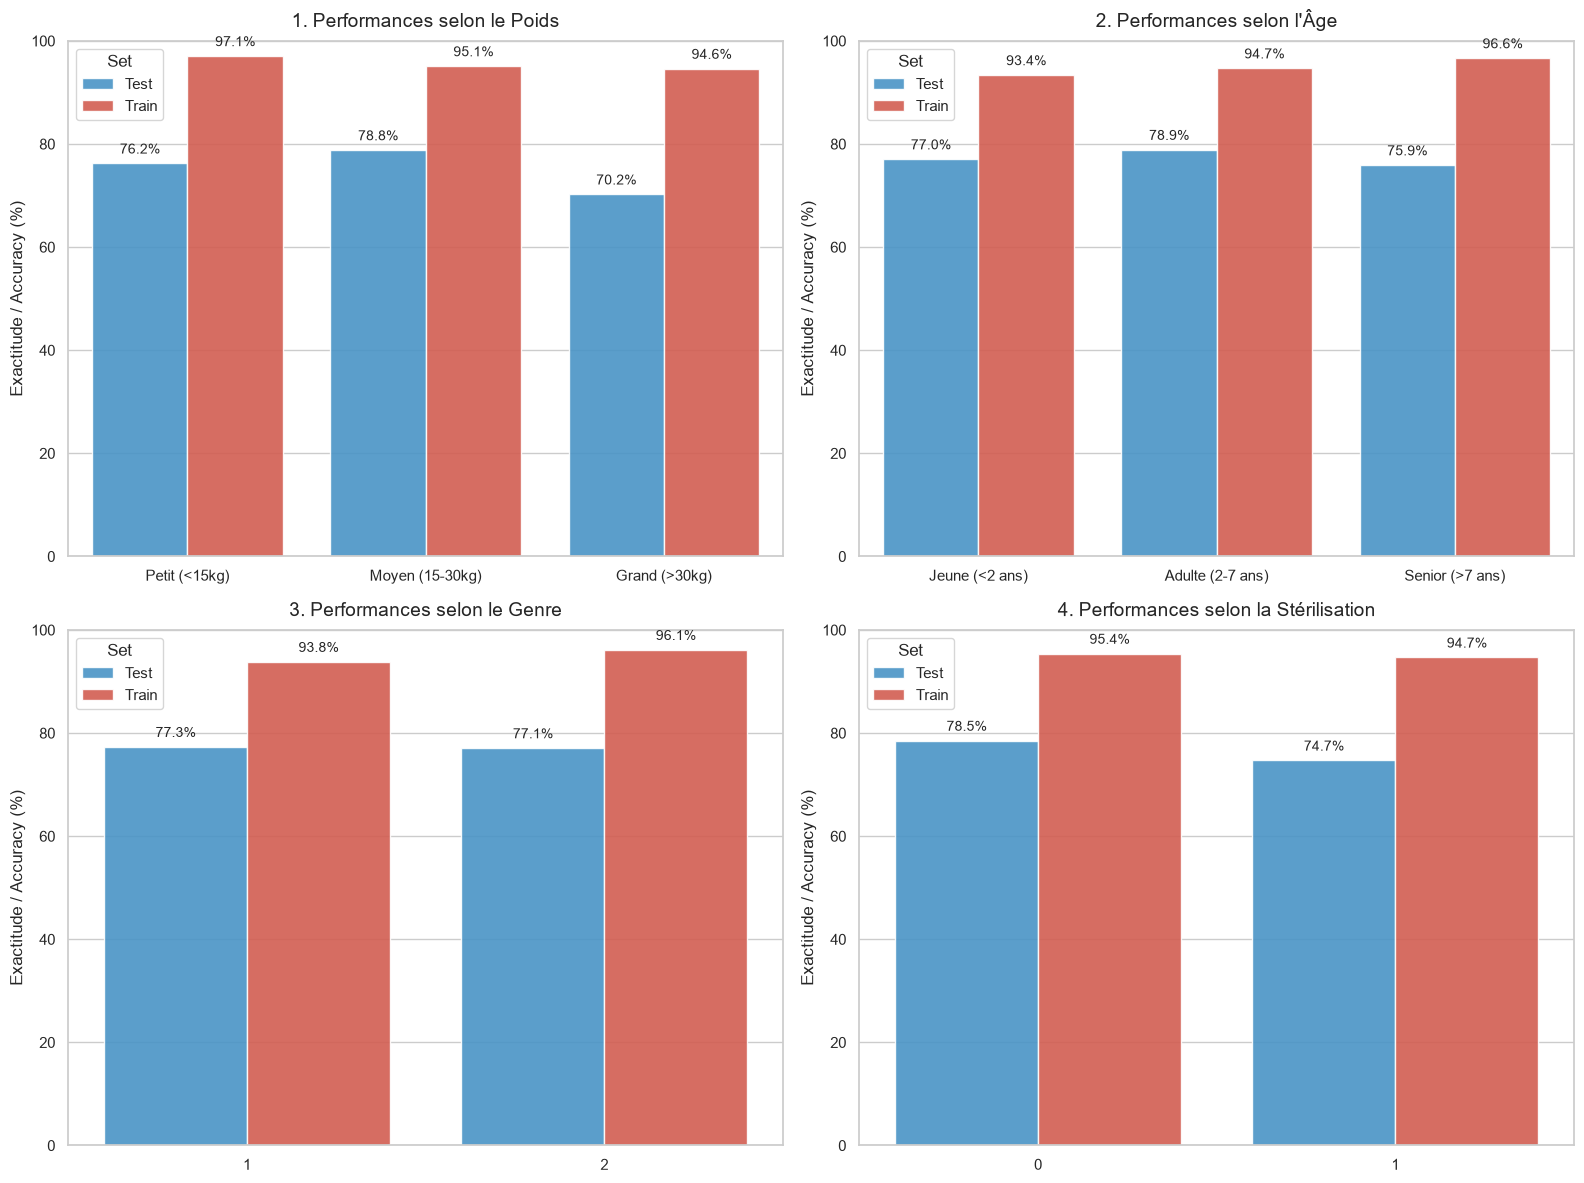

In [46]:
# ==========================================
# CELLULE 5 : Performances selon le profil du chien (Évaluation Multilabels)
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

print("1. Synchronisation de Behavior_2 et Behavior_3 depuis df_ts (cela peut prendre 10 à 20 secondes)...")

# Fonction utilitaire pour recréer B2 et B3 sur l'ensemble des datasets
def ajouter_multilabels(df_ml, df_ts_source, ws=100, ss=50):
    df_out = df_ml.copy()
    df_out['Behavior_2'] = None
    df_out['Behavior_3'] = None
    
    groupes = df_out.groupby(['DogID', 'TestNum']).groups
    
    for (dog_id, test_num), group_indices in groupes.items():
        mask_ts = (df_ts_source['DogID'] == dog_id) & (df_ts_source['TestNum'] == test_num)
        ts_session = df_ts_source[mask_ts]
        
        # Tri strict des index pour garantir que i correspond bien à la i-ème chronologique
        sorted_indices = sorted(group_indices)
        
        for i, idx in enumerate(sorted_indices):
            start = i * ss
            end = start + ws
            chunk = ts_session.iloc[start:end]
            
            if 'Behavior_2' in chunk.columns:
                b2_vals = chunk['Behavior_2'].dropna()
                if not b2_vals.empty:
                    df_out.at[idx, 'Behavior_2'] = b2_vals.mode()[0]
                    
            if 'Behavior_3' in chunk.columns:
                b3_vals = chunk['Behavior_3'].dropna()
                if not b3_vals.empty:
                    df_out.at[idx, 'Behavior_3'] = b3_vals.mode()[0]
                    
    return df_out

# On applique la fonction sur les datasets COMPLETS (avant filtrage pour garder la structure temporelle)
df_train_multi = ajouter_multilabels(df_train_ml, df_ts)
df_test_multi = ajouter_multilabels(df_test_ml, df_ts)

print("2. Calcul et validation des prédictions en cours...")

# Filtrage des datasets pour ne garder que les classes connues du modèle (>= 500)
classes_connues = encodeur_gagnant.classes_
df_train_eval = df_train_multi[df_train_multi['Behavior_encoded'].isin(classes_connues)].copy()
df_test_eval = df_test_multi[df_test_multi['Behavior_encoded'].isin(classes_connues)].copy()

# Prédictions (sorties de 0 à N-1)
y_pred_train_encoded = modele_gagnant.predict(df_train_eval[features_baseline])
y_pred_test_encoded = modele_gagnant.predict(df_test_eval[features_baseline])

# Décodage des prédictions pour revenir aux vrais labels d'origine (1 à 16)
y_pred_train = encodeur_gagnant.inverse_transform(y_pred_train_encoded)
y_pred_test = encodeur_gagnant.inverse_transform(y_pred_test_encoded)

# Création du dictionnaire de traduction (Code -> Texte)
df_all = pd.concat([df_train_ml, df_test_ml])
dict_traduction = dict(zip(df_all['Behavior_encoded'], df_all['Behavior']))

# Création de DataFrames de résultats simplifiés
res_train = df_train_eval[['DogID', 'Behavior_encoded', 'Behavior_2', 'Behavior_3']].copy()
res_train['Prediction_Code'] = y_pred_train
res_train['Set'] = 'Train'

res_test = df_test_eval[['DogID', 'Behavior_encoded', 'Behavior_2', 'Behavior_3']].copy()
res_test['Prediction_Code'] = y_pred_test
res_test['Set'] = 'Test'

# Fusion des prédictions
df_res = pd.concat([res_train, res_test], ignore_index=True)

# Traduction des codes en texte pour pouvoir comparer avec Behavior 2 et 3
df_res['Behavior_1_Text'] = df_res['Behavior_encoded'].map(dict_traduction)
df_res['Prediction_Text'] = df_res['Prediction_Code'].map(dict_traduction)

# NOUVELLE LOGIQUE : Une prédiction est correcte si elle est dans B1, B2 ou B3
def verifier_prediction_globale(row):
    labels_possibles = [row['Behavior_1_Text'], row['Behavior_2'], row['Behavior_3']]
    return int(row['Prediction_Text'] in labels_possibles)

df_res['Correct'] = df_res.apply(verifier_prediction_globale, axis=1)

print("3. Création des graphiques de performance...")

# Rapatriement des données statiques du chien (df_dogs)
df_profils = df_dogs[['DogID', 'Age months', 'Weight', 'Gender', 'NeuteringStatus']].copy()

# Recréation des classes de poids pour le graphique
bins_poids = [0, 15, 30, 100]
labels_poids = ['Petit (<15kg)', 'Moyen (15-30kg)', 'Grand (>30kg)']
df_profils['Classe_Poids'] = pd.cut(df_profils['Weight'], bins=bins_poids, labels=labels_poids, right=False)

# Création de classes d'âge pour le graphique
bins_age = [0, 24, 84, 300]
labels_age = ['Jeune (<2 ans)', 'Adulte (2-7 ans)', 'Senior (>7 ans)']
df_profils['Classe_Age'] = pd.cut(df_profils['Age months'], bins=bins_age, labels=labels_age, right=False)

# On associe chaque fenêtre temporelle au profil physique du chien correspondant
df_res_complet = df_res.merge(df_profils, on='DogID', how='left')

# Fonction utilitaire pour tracer les barplots
def plot_perf_by_category(df, col_x, ax, title):
    perf = df.groupby(['Set', col_x], observed=True)['Correct'].mean().reset_index()
    perf['Accuracy (%)'] = perf['Correct'] * 100
    
    sns.barplot(
        data=perf, 
        x=col_x, 
        y='Accuracy (%)', 
        hue='Set', 
        ax=ax, 
        palette=['#3498db', '#e74c3c'],
        alpha=0.9
    )
    
    ax.set_title(title, fontsize=14, pad=10)
    ax.set_ylim(0, 100)
    ax.set_ylabel("Exactitude / Accuracy (%)")
    ax.set_xlabel("")
    
    # Ajout des valeurs numériques sur les barres
    for p in ax.patches:
        hauteur = p.get_height()
        if pd.notnull(hauteur) and hauteur > 0:
            ax.annotate(f"{hauteur:.1f}%", 
                        (p.get_x() + p.get_width() / 2., hauteur), 
                        ha='center', va='bottom', fontsize=10, xytext=(0, 5), 
                        textcoords='offset points')

# Création et affichage de la grille de graphiques
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

plot_perf_by_category(df_res_complet, 'Classe_Poids', axes[0, 0], "1. Performances selon le Poids")
plot_perf_by_category(df_res_complet, 'Classe_Age', axes[0, 1], "2. Performances selon l'Âge")
plot_perf_by_category(df_res_complet, 'Gender', axes[1, 0], "3. Performances selon le Genre")
plot_perf_by_category(df_res_complet, 'NeuteringStatus', axes[1, 1], "4. Performances selon la Stérilisation")

plt.tight_layout()
plt.show()

### Matrices de confusion normalisées

Génération des matrices de confusion (Logique Flexible) en cours...


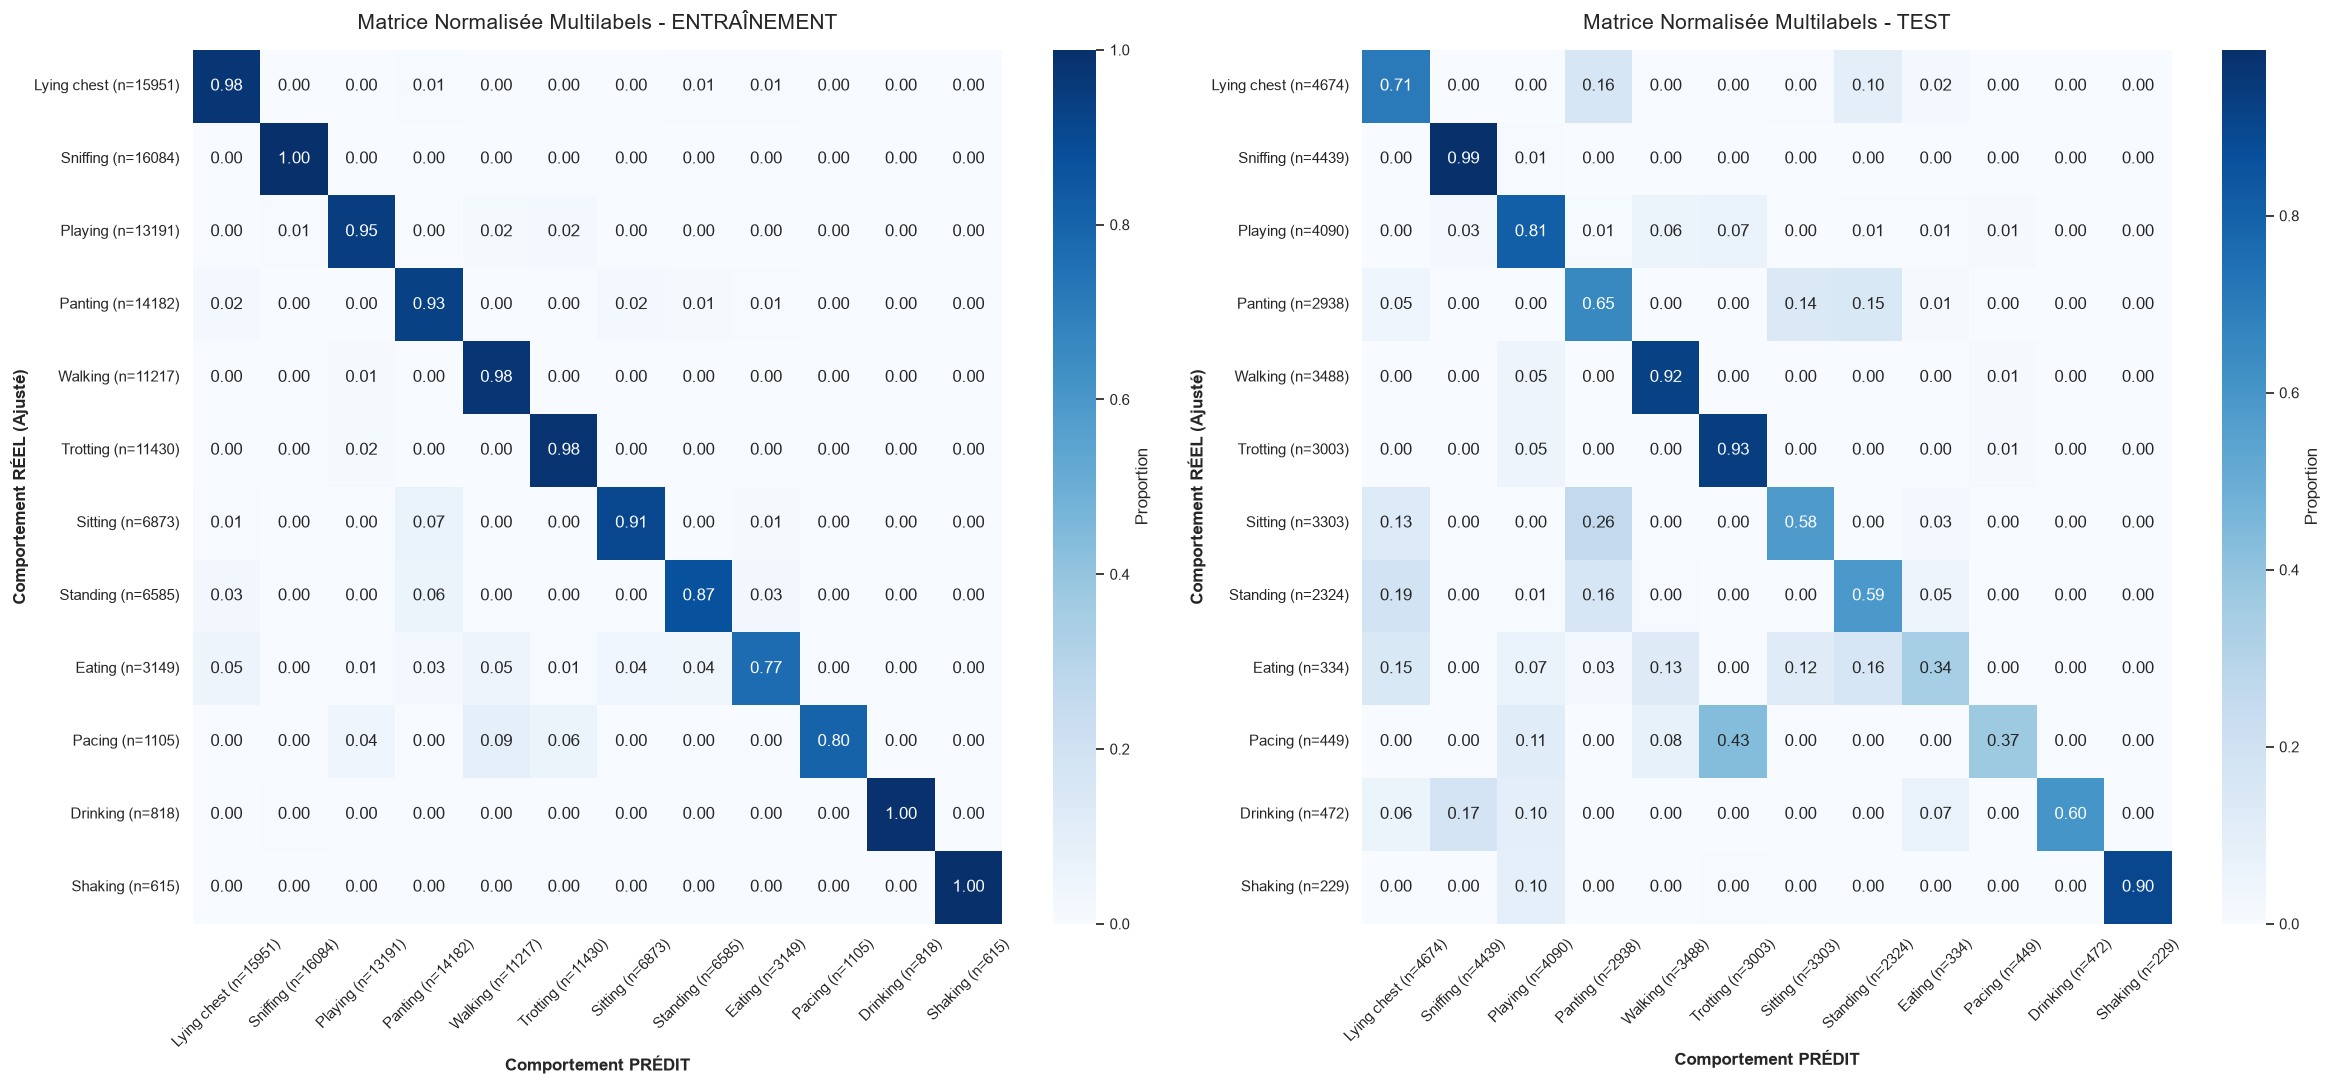

In [47]:
# ==========================================
# CELLULE 6 : Matrices de Confusion Normalisées (Évaluation Multilabels)
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import pandas as pd
import numpy as np

print("Génération des matrices de confusion (Logique Flexible) en cours...")

# 1. Vérification que la Cellule 5 a bien été exécutée pour avoir B2 et B3
if 'df_train_multi' not in locals() or 'df_test_multi' not in locals():
    raise NameError("Veuillez exécuter la Cellule 5 avant la Cellule 6 (pour générer df_train_multi et df_test_multi).")

# Filtrage des datasets pour ne garder que les classes connues du modèle (>= 500)
classes_connues = encodeur_gagnant.classes_
df_train_eval = df_train_multi[df_train_multi['Behavior_encoded'].isin(classes_connues)].copy()
df_test_eval = df_test_multi[df_test_multi['Behavior_encoded'].isin(classes_connues)].copy()

# 2. Prédictions (de 0 à N-1)
y_train_pred_encoded = modele_gagnant.predict(df_train_eval[features_baseline])
y_test_pred_encoded = modele_gagnant.predict(df_test_eval[features_baseline])

# Retour aux codes d'origine (1 à 16) pour faire le lien
df_train_eval['Prediction_Code'] = encodeur_gagnant.inverse_transform(y_train_pred_encoded)
df_test_eval['Prediction_Code'] = encodeur_gagnant.inverse_transform(y_test_pred_encoded)

# 3. Traduction pour la comparaison textuelle
df_all = pd.concat([df_train_ml, df_test_ml])
dict_traduction = dict(zip(df_all['Behavior_encoded'], df_all['Behavior']))

df_train_eval['Prediction_Text'] = df_train_eval['Prediction_Code'].map(dict_traduction)
df_test_eval['Prediction_Text'] = df_test_eval['Prediction_Code'].map(dict_traduction)

# 4. CRÉATION DES VRAIS LABELS "FLEXIBLES"
def ajuster_vrai_label_code(row):
    pred_text = row['Prediction_Text']
    b1 = row['Behavior']
    b2 = row['Behavior_2']
    b3 = row['Behavior_3']
    
    # Si la prédiction tape juste sur B1, B2 ou B3 -> On force la diagonale
    if pred_text in [b1, b2, b3]:
        return row['Prediction_Code'] 
    else:
        # S'il a complètement tort -> On impute l'erreur au comportement principal (B1)
        return row['Behavior_encoded'] 

# Application de la règle
y_train_true_flex = df_train_eval.apply(ajuster_vrai_label_code, axis=1).values
y_test_true_flex = df_test_eval.apply(ajuster_vrai_label_code, axis=1).values

# Encodage final (0 à N-1) pour Scikit-Learn
y_train_true = encodeur_gagnant.transform(y_train_true_flex)
y_test_true = encodeur_gagnant.transform(y_test_true_flex)
y_train_pred = y_train_pred_encoded
y_test_pred = y_test_pred_encoded

# 5. Calcul des fréquences pour l'ordre ET pour l'affichage (basé sur nos nouveaux vrais labels)
y_all_true = np.concatenate([y_train_true, y_test_true])
comptage_global = pd.Series(y_all_true).value_counts()
classes_triees = comptage_global.index.tolist() # Ordre de tri basé sur le volume total

comptage_train = pd.Series(y_train_true).value_counts()
comptage_test = pd.Series(y_test_true).value_counts()

# Génération des étiquettes textuelles séparées
labels_text_train = []
labels_text_test = []

for c in classes_triees:
    code_original = encodeur_gagnant.classes_[c]
    nom_comportement = dict_traduction[code_original]
    
    n_train = comptage_train.get(c, 0)
    n_test = comptage_test.get(c, 0)
    
    labels_text_train.append(f"{nom_comportement} (n={n_train})")
    labels_text_test.append(f"{nom_comportement} (n={n_test})")

# 6. Fonction utilitaire
def plot_matrice_confusion(y_true, y_pred, ordre_classes, labels_text, title, ax):
    cm = confusion_matrix(y_true, y_pred, labels=ordre_classes, normalize='true')
    
    sns.heatmap(
        cm, annot=True, fmt=".2f", cmap="Blues",
        xticklabels=labels_text, yticklabels=labels_text, 
        cbar_kws={'label': 'Proportion'}, ax=ax
    )
    
    ax.set_title(title, fontsize=15, pad=15)
    ax.set_xlabel("Comportement PRÉDIT", fontsize=12, fontweight='bold')
    ax.set_ylabel("Comportement RÉEL (Ajusté)", fontsize=12, fontweight='bold')
    ax.tick_params(axis='x', rotation=45) 
    ax.tick_params(axis='y', rotation=0)

# 7. Affichage
fig, axes = plt.subplots(1, 2, figsize=(24, 11))

plot_matrice_confusion(y_train_true, y_train_pred, classes_triees, labels_text_train, "Matrice Normalisée Multilabels - ENTRAÎNEMENT", axes[0])
plot_matrice_confusion(y_test_true, y_test_pred, classes_triees, labels_text_test, "Matrice Normalisée Multilabels - TEST", axes[1])

plt.subplots_adjust(bottom=0.2)
plt.tight_layout()
plt.show()

### F1-score macro

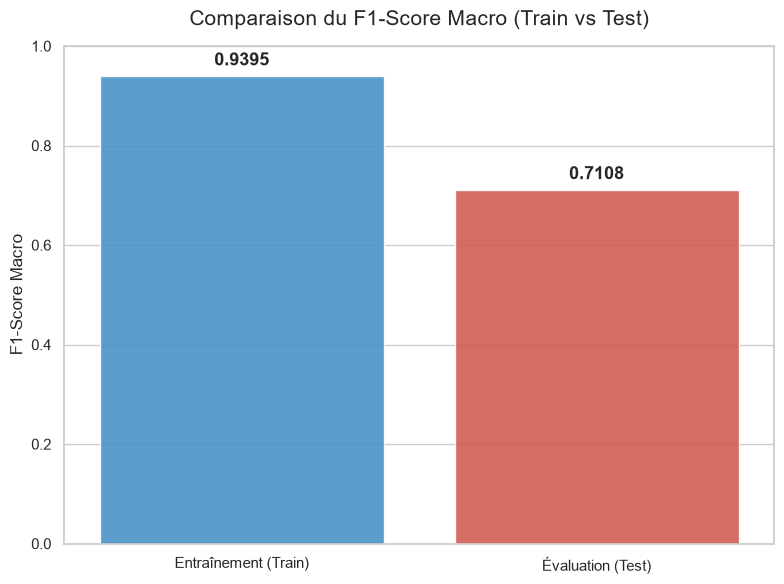

In [48]:
# ==========================================
# CELLULE 7 : Visualisation du F1-Score Macro (Overfitting Check)
# ==========================================
from sklearn.metrics import f1_score
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calcul des scores (en utilisant les variables déjà filtrées de la Cellule 6)
f1_train = f1_score(y_train_true, y_train_pred, average='macro', zero_division=0)
f1_test = f1_score(y_test_true, y_test_pred, average='macro', zero_division=0)

df_f1 = pd.DataFrame({
    'Sous-ensemble': ['Entraînement (Train)', 'Évaluation (Test)'],
    'F1-Score Macro': [f1_train, f1_test]
})

# 2. Visualisation
plt.figure(figsize=(8, 6))
sns.set_theme(style="whitegrid")

# Ajout de hue='Sous-ensemble' et legend=False pour éviter le FutureWarning de Seaborn
ax = sns.barplot(
    data=df_f1, 
    x='Sous-ensemble', 
    y='F1-Score Macro', 
    hue='Sous-ensemble',
    legend=False,
    palette=['#3498db', '#e74c3c'],
    alpha=0.9
)

plt.title("Comparaison du F1-Score Macro (Train vs Test)", fontsize=15, pad=15)
plt.ylim(0, 1.0) # Le F1-score est compris entre 0 et 1
plt.ylabel("F1-Score Macro")
plt.xlabel("")

# Ajout des valeurs exactes sur les barres
for p in ax.patches:
    hauteur = p.get_height()
    if pd.notnull(hauteur) and hauteur > 0:
        ax.annotate(f"{hauteur:.4f}", 
                    (p.get_x() + p.get_width() / 2., hauteur), 
                    ha='center', va='bottom', fontsize=13, fontweight='bold', xytext=(0, 5), 
                    textcoords='offset points')

plt.tight_layout()
plt.show()

### Courbes d'Apprentissage (Learning Curves) de XGBoost baseline (modèle retenu)

Génération des courbes d'apprentissage en cours...
🔄 Chargement du modèle depuis le disque :
   C:\Users\Cours APT\Documents\dog-behavior-analysis\models_1_ws=100_ss=50\XGBoost_baseline.joblib
✅ Modèle XGBoost et encodeur chargés avec succès !


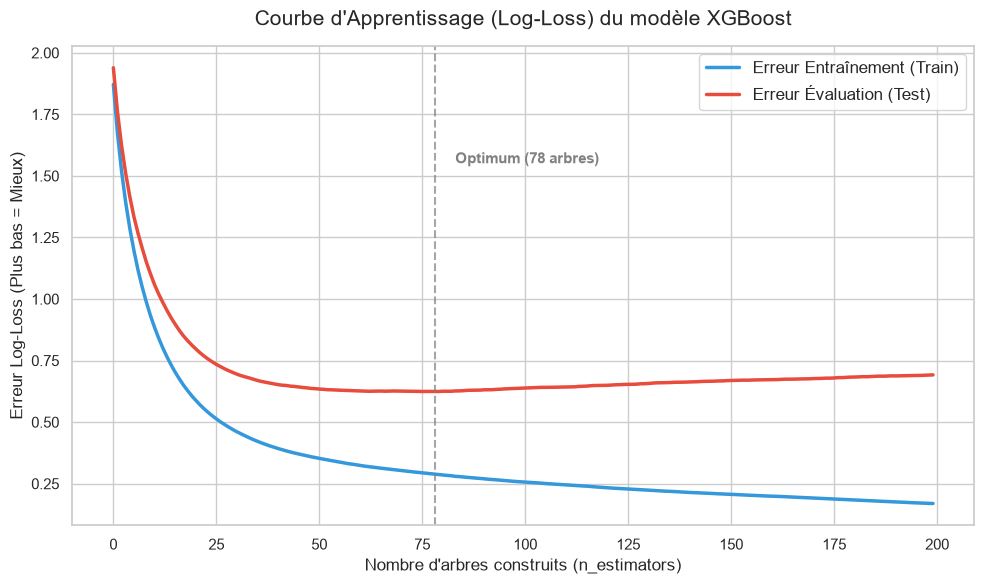

In [50]:
# ==========================================
# CELLULE 8 : Courbes d'Apprentissage (Learning Curves) de XGBoost
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone

print("Génération des courbes d'apprentissage en cours...")

# ==========================================
# CHARGEMENT DIRECT DU MEILLEUR MODÈLE
# ==========================================
chemin_disque = r"C:\Users\Cours APT\Documents\dog-behavior-analysis\models_1_ws=100_ss=50\XGBoost_baseline.joblib"
print(f"🔄 Chargement du modèle depuis le disque :\n   {chemin_disque}")

modele_gagnant = joblib.load(chemin_disque)

comptage_classes = df_train_ml['Behavior_encoded'].value_counts()
classes_valides = comptage_classes[comptage_classes >= 500].index

encodeur_gagnant = LabelEncoder()
df_train_filtr = df_train_ml[df_train_ml['Behavior_encoded'].isin(classes_valides)]
encodeur_gagnant.fit(df_train_filtr['Behavior_encoded'])
print("✅ Modèle XGBoost et encodeur chargés avec succès !")

# 1. Filtrage strict (on s'entraîne sur les données pures)
classes_connues = encodeur_gagnant.classes_
df_train_eval = df_train_ml[df_train_ml['Behavior_encoded'].isin(classes_connues)].copy()
df_test_eval = df_test_ml[df_test_ml['Behavior_encoded'].isin(classes_connues)].copy()

X_train_brut = df_train_eval[features_baseline]
y_train = encodeur_gagnant.transform(df_train_eval['Behavior_encoded'])

X_test_brut = df_test_eval[features_baseline]
y_test = encodeur_gagnant.transform(df_test_eval['Behavior_encoded'])

# 2. Extraction des étapes de la Pipeline gagnante
# On récupère le bloc de préparation (StandardScaler + SelectFromModel)
preprocesseur = modele_gagnant[:-1]
# On récupère les hyperparamètres du XGBoost final
modele_xgb_original = modele_gagnant.steps[-1][1]

# 3. Application de la préparation des données
X_train_trans = preprocesseur.transform(X_train_brut)
X_test_trans = preprocesseur.transform(X_test_brut)

# 4. Clonage du modèle XGBoost pour le réentraîner de zéro
xgb_clone = clone(modele_xgb_original)

# On force l'évaluation de la métrique Log-Loss (Erreur logistique)
xgb_clone.set_params(eval_metric='mlogloss')

# Ré-entraînement en observant l'erreur sur le Train et le Test à CHAQUE arbre
xgb_clone.fit(
    X_train_trans, y_train,
    eval_set=[(X_train_trans, y_train), (X_test_trans, y_test)],
    verbose=False
)

# 5. Récupération de l'historique des métriques
resultats = xgb_clone.evals_result_
epochs = len(resultats['validation_0']['mlogloss'])
x_axis = range(0, epochs)

# 6. Tracé de la courbe
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# validation_0 correspond au jeu d'entraînement, validation_1 au jeu de test
plt.plot(x_axis, resultats['validation_0']['mlogloss'], label='Erreur Entraînement (Train)', color='#3498db', linewidth=2.5)
plt.plot(x_axis, resultats['validation_1']['mlogloss'], label='Erreur Évaluation (Test)', color='#e74c3c', linewidth=2.5)

plt.title("Courbe d'Apprentissage (Log-Loss) du modèle XGBoost", fontsize=15, pad=15)
plt.xlabel("Nombre d'arbres construits (n_estimators)", fontsize=12)
plt.ylabel("Erreur Log-Loss (Plus bas = Mieux)", fontsize=12)
plt.legend(fontsize=12)

# Ajout d'une ligne verticale pour repérer le point optimal du test
min_test_loss_idx = resultats['validation_1']['mlogloss'].index(min(resultats['validation_1']['mlogloss']))
plt.axvline(x=min_test_loss_idx, color='gray', linestyle='--', alpha=0.7)
plt.text(min_test_loss_idx + 5, max(resultats['validation_1']['mlogloss'])*0.8, 
         f'Optimum ({min_test_loss_idx} arbres)', color='gray', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()